In [1]:
!pip install -q dtreeviz

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import dtreeviz
from sklearn.datasets import load_iris, load_diabetes
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

In [3]:
iris = load_iris()
X_iris, y_iris = iris.data, iris.target
class_names = list(iris.target_names)

clas = DecisionTreeClassifier(random_state=0)
clas.fit(X_iris, y_iris)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current 

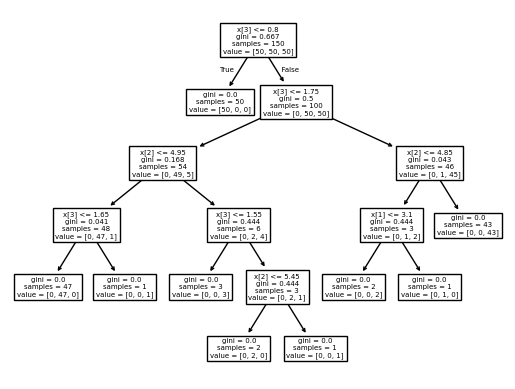

In [4]:
plot_tree(clas);

# 1. Classification

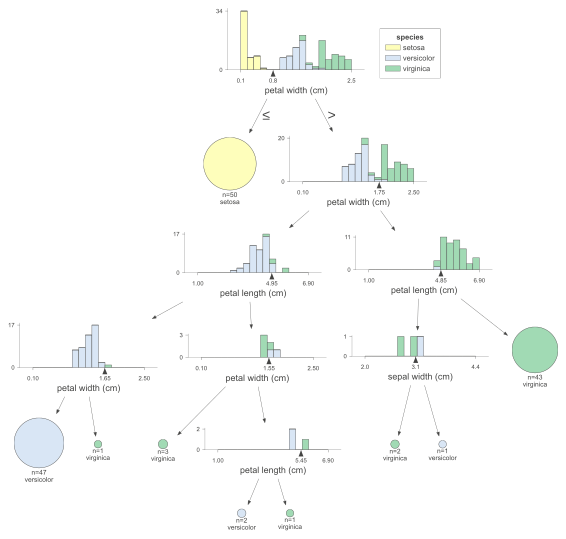

In [6]:
viz_model = dtreeviz.model(clas, X_iris, y_iris,
                          feature_names=iris.feature_names,
                          target_name='species',
                          class_names=class_names)
viz_model.view()

# 2. Regression

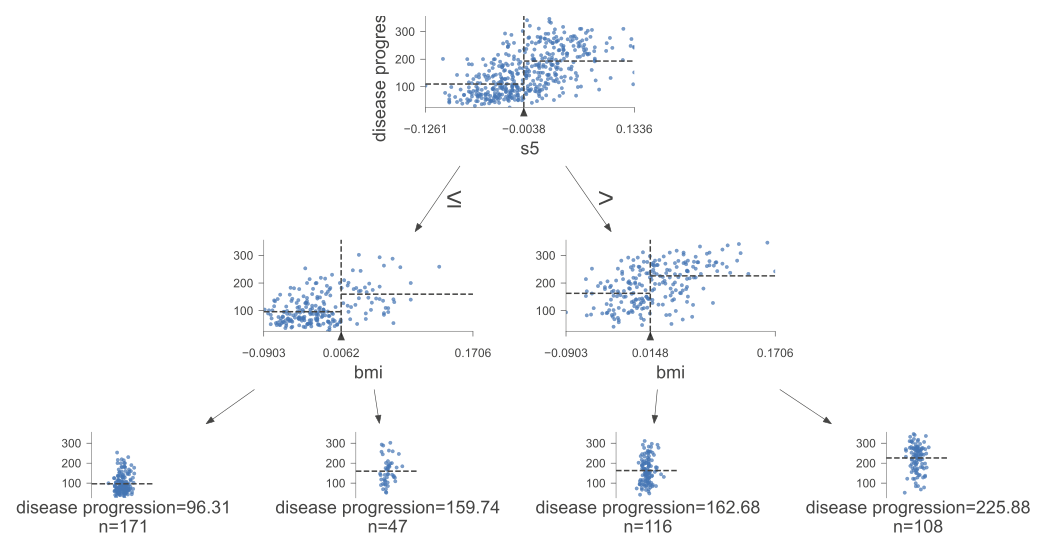

In [7]:
diabetes = load_diabetes()
X_reg, y_reg = diabetes.data, diabetes.target

regr = DecisionTreeRegressor(max_depth=2, random_state=0)
regr.fit(X_reg, y_reg)

viz_reg = dtreeviz.model(regr, X_reg, y_reg,
                         target_name='disease progression',
                         feature_names=diabetes.feature_names)
viz_reg.view(scale=2)

# 3. Horizontal Decision Tree

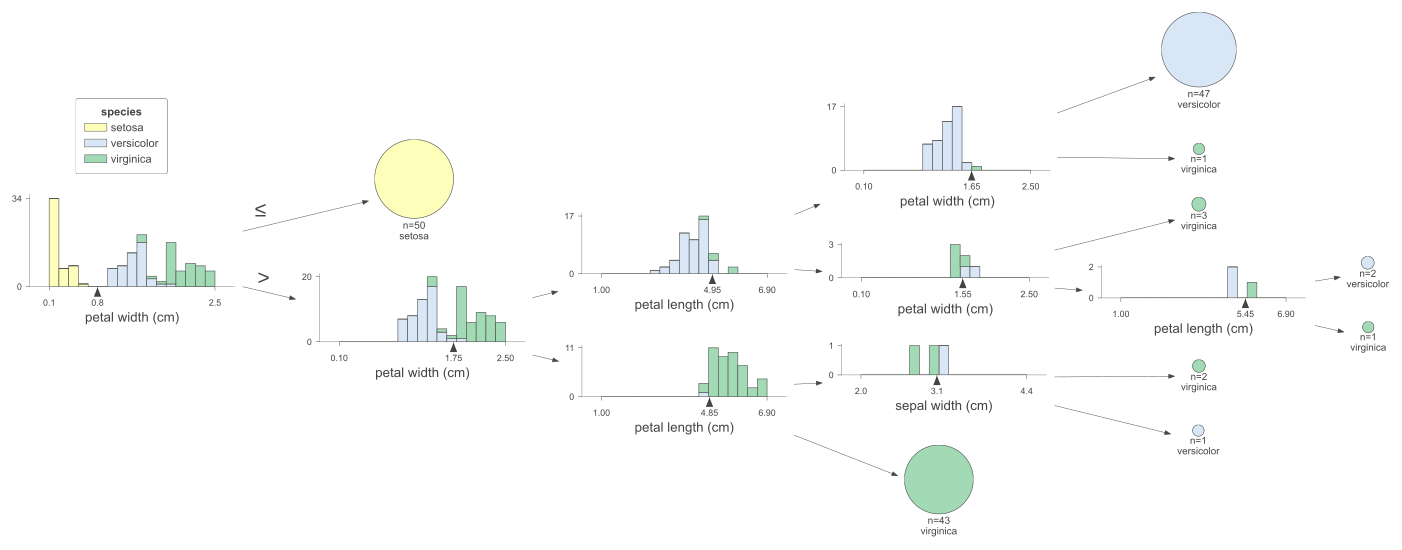

In [8]:
viz_model.view(scale=1.5, orientation='LR')

# 4. Show prediction path

In [9]:
rng = np.random.default_rng(0)
x = X_iris[rng.integers(0, len(X_iris))]
x

array([6.1, 3. , 4.9, 1.8])

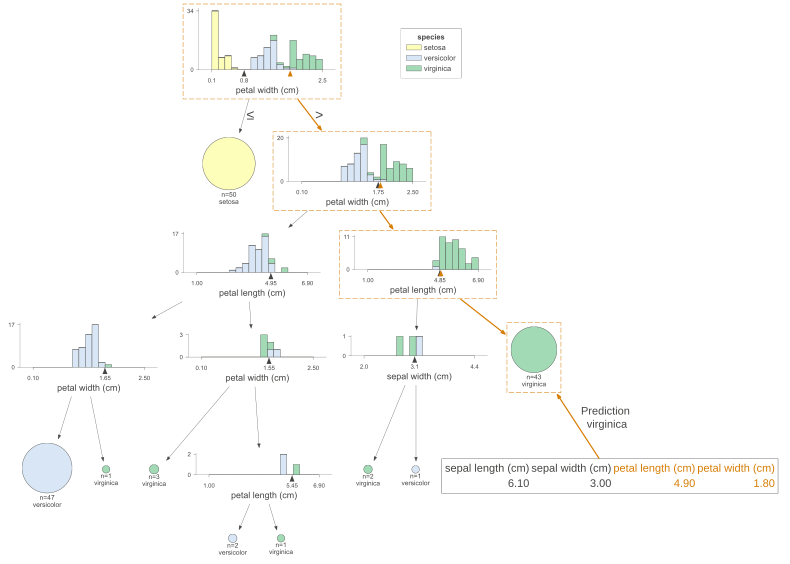

In [10]:
viz_model.view(x=x)

# 5. Show node number

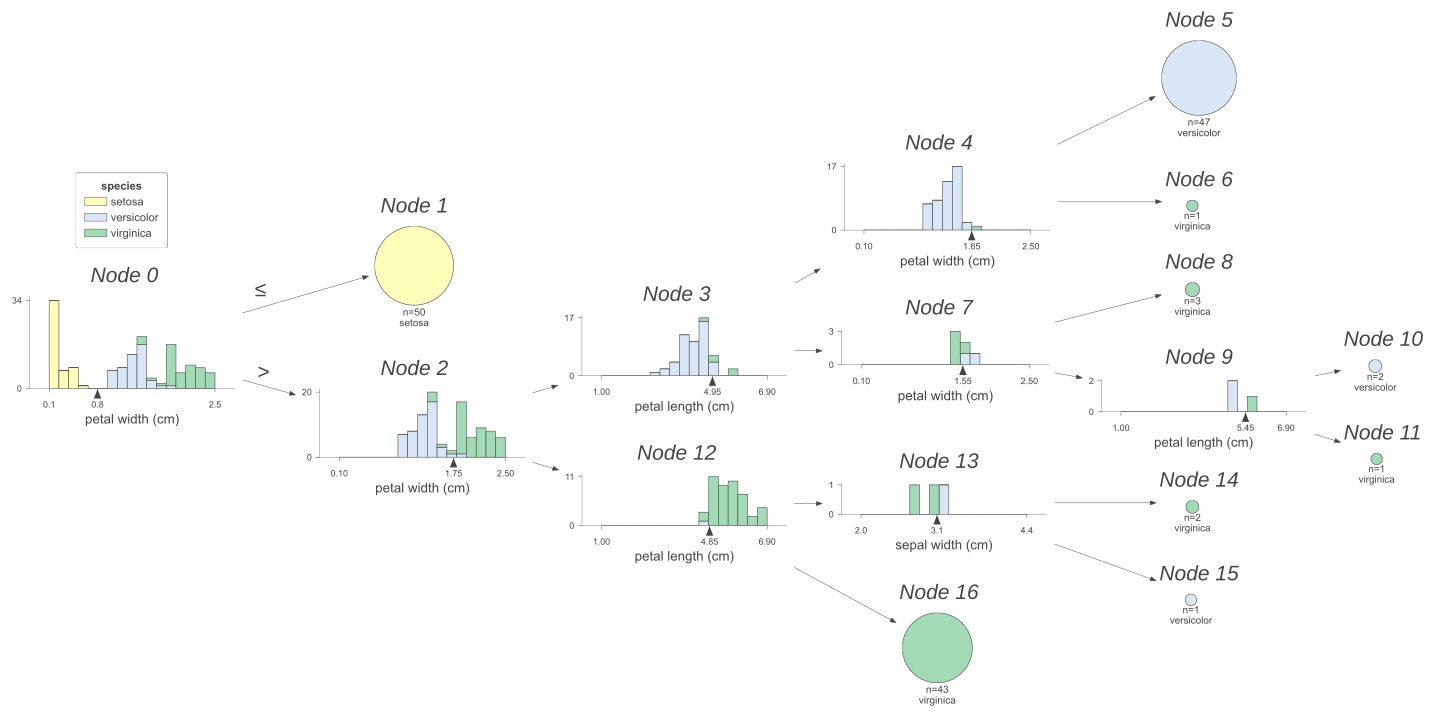

In [11]:
viz_model.view(histtype='barstacked', scale=1.5, orientation='LR', show_node_labels=True)

# 6. Without Any graphs

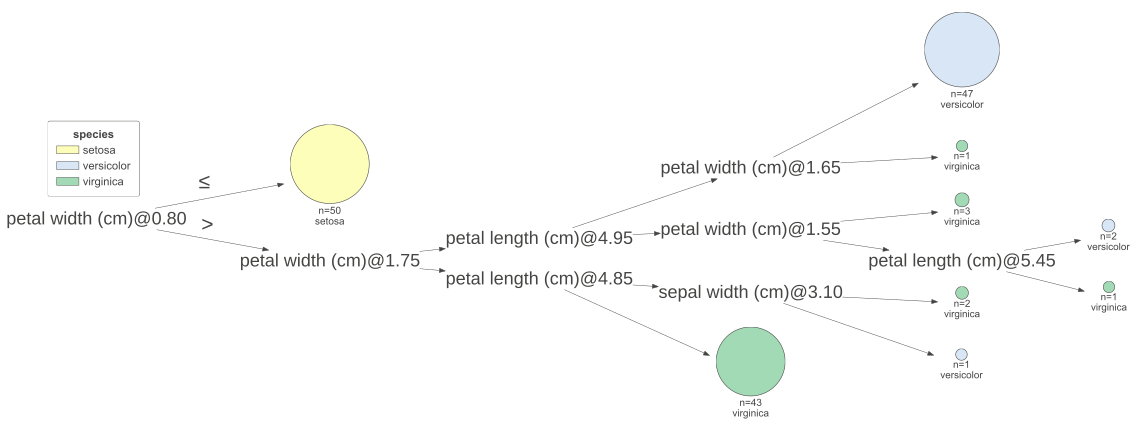

In [12]:
viz_model.view(fancy=False, scale=1.5, orientation='LR')

# 7. Show just prediction path, nothing else

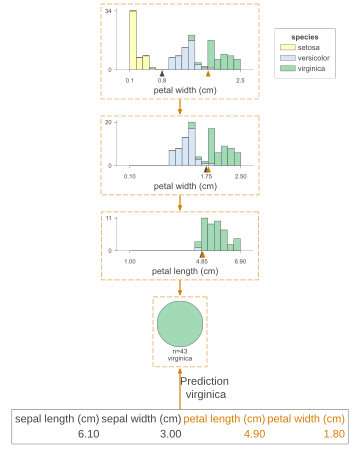

In [13]:
viz_model.view(x=x, show_just_path=True)

# 8. Prediction Path in Plain english

In [14]:
print(viz_model.explain_prediction_path(x))

4.85 <= petal length (cm) 
1.75 <= petal width (cm) 



# 9. Feature Importance

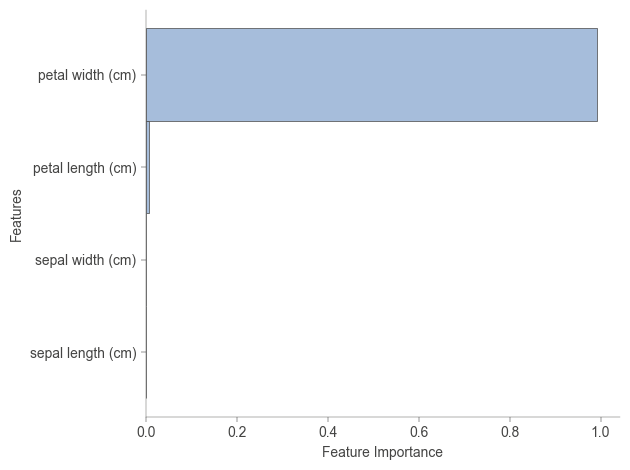

In [15]:
viz_model.instance_feature_importance(x);

# 10. Univariate Regression

The original used `cars.csv`, which isn't shipped with the notebook, so the diabetes data (BMI vs. disease progression) is used. Note `criterion="mae"` is now `"absolute_error"`.

In [16]:
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


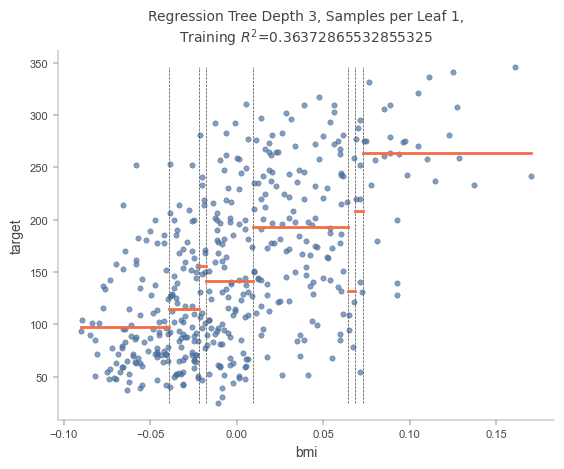

In [17]:
X_uni, y_uni = df[['bmi']], df['target']

dt = DecisionTreeRegressor(max_depth=3, criterion="absolute_error", random_state=0)
dt.fit(X_uni, y_uni)

viz_uni = dtreeviz.model(dt, X_uni, y_uni, target_name='target', feature_names=['bmi'])
viz_uni.rtree_feature_space(features=['bmi'])
plt.show()

# 11. 3-D Regression

C:\Users\LOQ\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


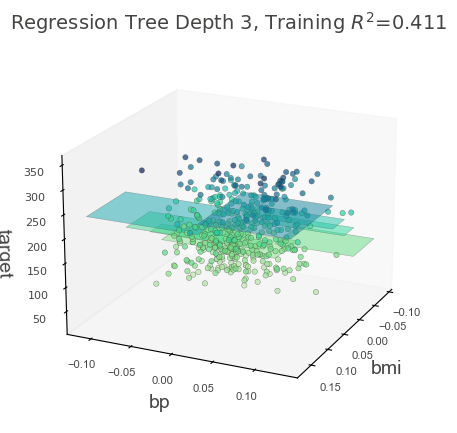

In [18]:
X_bi, y_bi = df[['bmi', 'bp']], df['target']

dt = DecisionTreeRegressor(max_depth=3, criterion="absolute_error", random_state=0)
dt.fit(X_bi, y_bi)

viz_bi = dtreeviz.model(dt, X_bi, y_bi, target_name='target', feature_names=['bmi', 'bp'])
viz_bi.rtree_feature_space3D(features=['bmi', 'bp'],
                             fontsize=14, elev=20, azim=25, dist=8.2,
                             show={'splits', 'title'},
                             figsize=(6, 5))
plt.show()